# Government schools in NSW and SA, compared the same way

**The question.** Do inner Sydney and inner Adelaide schools get the same grounds per student, measured the same way,
and how do the two systems compare on spending, staffing and outcomes?

This notebook compares government schools in New South Wales and South Australia: spend per student, the split of that
spend, school assets, students per teaching staff member, attendance, retention, NAPLAN, and the grounds per student
in the inner city. It reads only the files in `../data`, recomputes every number it shows, and checks the headline
numbers at the end.

**Sources.** State figures: Steering Committee for the Review of Government Service Provision, Report on Government
Services 2026 (Productivity Commission), Part B section 4, CC BY 4.0. NAPLAN: ACARA national results, CC BY 4.0, all
school sectors. Enrolments: NSW Department of Education (CC BY), August headcount; Department for Education SA
(CC BY 4.0), Term 3 FTE. School outlines made in [Plotlay](https://www.getplotlay.com): in Sydney from NSW Cadastre lots
and NSW Imagery (© Spatial Services NSW, CC BY 3.0 AU), in Adelaide from SA Land Use Generalised 2025 (DHUD, CC BY),
City of Adelaide parcels (CC BY 4.0) and DEW 2022 rasters (CC BY 4.0). There is no OpenStreetMap data in this
repository and the maps use no basemap tiles.

**The rule.** SA appears only alongside the identical NSW analysis. Every function is defined once, below. Section 1
calls each one for NSW; section 2 makes exactly the same calls with the state changed to SA; section 3 calls the same
functions with both states and works out the SA minus NSW gaps.

**Read with these caveats.**

- Enrolments: NSW counts students by **headcount**, SA by **FTE** (full-time equivalent). The state-level ROGS figures
  are per FTE student in both states.
- SA moved **Year 7 from primary to high school in 2022**. Primary and secondary series in SA change base that year
  (students per teaching staff member, retention from Year 7 or 8, inner-city enrolments by level). NSW has always had
  Year 7 in high school.
- **Staged openings.** A school without all its year groups in 2024 is shown but left out of the medians, in both
  cities. Inner Sydney High opened in 2020 with Year 7 and added a year group each year; 2025 is its first year with
  Years 7 to 12, so it is left out in 2024. It is also a 14-storey vertical school, so its grounds per student are not a
  fair comparison with low-rise schools in any year (see
  [Inner Sydney High, a deep dive](https://www.getplotlay.com/showcase/inner-sydney-high/)). Adelaide Botanic High
  (opened 2019 with Years 8 and 9) has had every year group since 2022, so it is compared.
- NAPLAN moved to a **new scale in 2023** (and to a March test). The 2008 to 2022 and 2023 to 2026 results are drawn on
  separate panels and never joined. NAPLAN figures here are **all school sectors**, not government schools only.
- **Grounds** means the land a school sits on, buildings included. It is not floor space and not playground area.
  Areas are approximate: accuracy depends on the cadastre, parcels and imagery the outlines came from.
- **Not the Sydney showcase's numbers.** This notebook uses the 86 government schools within 7 km of Sydney Town Hall
  and 2024 students (NSW August headcount, SA Term 3 FTE). The
  [Sydney schools showcase](https://www.getplotlay.com/showcase/sydney-schools/) uses 81 schools across inner Sydney and
  Parramatta and 2025 headcount, so its medians differ.
- Measures are shown side by side. **No cause and effect** is claimed between any of them.

In [1]:
import warnings
warnings.filterwarnings('ignore')      # library notices print install paths; none of them changes a result
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, Circle

DATA = '../data'
pd.set_option('display.width', 160); pd.set_option('display.max_colwidth', None)
COL = {'NSW': '#1d4f91', 'SA': '#c0702a'}
PAPER, TEXT, MUTED, GRID, GREY = '#f2efe6', '#1f2a37', '#5b6573', '#d9d4c7', '#bdb8ac'
CITY = {'NSW': 'Sydney', 'SA': 'Adelaide'}
OUTLINES = {'NSW': 'nsw/sydney_outlines_joined.geojson', 'SA': 'sa/adelaide_outlines_joined.geojson'}
CENTRE = {'NSW': (151.2061, -33.8732, 'Sydney Town Hall'), 'SA': (138.6007, -34.9285, 'Victoria Square')}
ALBERS = 9473                                     # GDA2020 Australian Albers, an equal-area grid in metres
BINS = [0, 15, 30, 60, np.inf]
BIN_LABELS = ['under 15 m²', '15 to 30', '30 to 60', '60 m² or more']
BIN_COLOURS = ['#7a1c10', '#c8452a', '#ef9a6c', '#f7d9c2']
EXCL, INCL = 'Total recurrent expenditure excluding user cost of capital', 'Total recurrent expenditure including user cost of capital'
plt.rcParams.update({'figure.dpi': 100, 'figure.facecolor': PAPER, 'axes.facecolor': PAPER, 'savefig.facecolor': PAPER,
                     'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10, 'text.color': TEXT,
                     'axes.labelcolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED, 'axes.edgecolor': MUTED})
money = lambda x, _=None: f'${x:,.0f}'
pct = lambda x, _=None: f'{x:.0f}%'

def rd(state, name):
    """One of the state's own tables: data/nsw/<name> or data/sa/<name>."""
    return pd.read_csv(f'{DATA}/{state.lower()}/{name}')

def grid(ax, axis='y'):
    ax.grid(axis=axis, color=GRID, lw=0.8); ax.set_axisbelow(True)

def title(ax, t, sub):
    ax.set_title(t + '\n', loc='left', fontsize=12, fontweight='bold')
    ax.text(0, 1.02, sub, transform=ax.transAxes, fontsize=9, color=MUTED, va='bottom')

In [2]:
# State-level measures (ROGS and ACARA), one function each

def spend_series(state):
    """Real recurrent spend per FTE government school student, 2023-24 dollars, all school levels."""
    d = rd(state, '01_spend_per_student_components.csv')
    d = d[d.school_level == 'All school levels'].pivot(index='financial_year', columns='component', values='dollars_per_fte_student')
    return d[[EXCL, INCL]].rename(columns={EXCL: 'excluding UCC', INCL: 'including UCC'}).sort_index()

def plot_spend(states):
    fig, ax = plt.subplots(figsize=(8, 3.8))
    for s in states:
        d = spend_series(s); x = range(len(d))
        ax.plot(x, d['excluding UCC'], color=COL[s], lw=2.4, label=f'{s} excluding UCC')
        ax.plot(x, d['including UCC'], color=COL[s], lw=1.6, ls=(0, (6, 3)), label=f'{s} including UCC')
        for col in d: ax.annotate(f"${d[col].iloc[-1]:,.0f}", (len(d) - 1, d[col].iloc[-1]), xytext=(5, 0), textcoords='offset points', va='center', fontsize=9, color=COL[s])
    ax.set_xticks(range(len(d)), d.index, rotation=0, fontsize=8); ax.set_ylim(0, 30000); ax.set_xlim(-0.3, len(d) + 0.6)
    ax.yaxis.set_major_formatter(money); grid(ax); ax.legend(frameon=False, ncol=2, loc='lower left', fontsize=9)
    title(ax, 'Real recurrent spend per FTE student', '2014-15 to 2023-24, 2023-24 dollars. UCC: user cost of capital, a notional cost of the capital tied up in schools.')
    plt.show()

COMPONENTS = [('Employee related expenditure: Teachers', 'Teachers', '#1d4f91'), ('Employee related expenditure: Other Staff', 'Other staff', '#1baf7a'),
              ('Other operating expenses', 'Operating costs', '#eda100'), ('Depreciation', 'Depreciation', '#e87ba4'), ('User cost of capital', 'User cost of capital', GRID)]

def spend_split(state, year='2023-24'):
    d = rd(state, '01_spend_per_student_components.csv')
    d = d[(d.school_level == 'All school levels') & (d.financial_year == year)].set_index('component').dollars_per_fte_student
    out = pd.Series({lab: d[c] for c, lab, _ in COMPONENTS})
    # the parts add to the published totals, give or take the rounding of each part to whole dollars
    assert abs(out.drop('User cost of capital').sum() - d[EXCL]) <= 3 and abs(out.sum() - d[INCL]) <= 3, 'parts and totals disagree'
    return out

def plot_spend_split(states):
    fig, ax = plt.subplots(figsize=(8, 1.2 + 0.8 * len(states)))
    for i, s in enumerate(states):
        y, left, d = len(states) - 1 - i, 0, spend_split(s)
        for (c, lab, colour) in COMPONENTS:
            v = d[lab]
            ax.barh(y, v, left=left, height=0.55, color=colour, hatch='////' if lab == 'User cost of capital' else None, edgecolor=PAPER, label=lab if i == 0 else None)
            if v > 1700: ax.text(left + v / 2, y, f'${v:,.0f}', ha='center', va='center', fontsize=8.5, color='white' if lab == 'Teachers' else TEXT)
            left += v
        ax.text(left + 300, y, f'${left:,.0f}', va='center', fontsize=9)
    ax.set_yticks(range(len(states)), states[::-1]); ax.set_xlim(0, 32000); ax.xaxis.set_major_formatter(money); grid(ax, 'x')
    ax.legend(frameon=False, ncol=5, loc='upper left', bbox_to_anchor=(0, -0.25), fontsize=8.5)
    title(ax, 'Where the money goes, 2023-24', 'Recurrent spend per FTE student by component. States classify some staff differently.')
    plt.show()

def assets(state, year='2023-24'):
    """Written-down value of government school land and buildings per FTE student, 30 June 2024."""
    d = rd(state, '03_school_assets_per_student.csv')
    return d[d.financial_year == year].set_index('asset').dollars_per_fte_student.rename(state)

def plot_assets(states):
    fig, ax = plt.subplots(figsize=(4 + 1.2 * len(states), 3.8))
    for i, s in enumerate(states):
        a = assets(s); la, bu = a['Land'], a['Buildings; equipment and other']
        ax.bar(i, la, width=0.5, color=COL[s], alpha=0.45, edgecolor=PAPER); ax.bar(i, bu, bottom=la, width=0.5, color=COL[s], edgecolor=PAPER)
        ax.text(i, la / 2, f'land\n${la:,.0f}', ha='center', va='center', fontsize=8.5)
        ax.text(i, la + bu / 2, f'buildings and\nequipment\n${bu:,.0f}', ha='center', va='center', fontsize=8.5, color='white')
        ax.text(i, la + bu + 1200, f"${a['Total']:,.0f}", ha='center', fontsize=10, fontweight='bold')
    ax.set_xticks(range(len(states)), states); ax.set_xlim(-0.7, max(len(states), 2) - 0.3); ax.set_ylim(0, 70000)
    ax.yaxis.set_major_formatter(money); grid(ax)
    title(ax, 'School assets per FTE student', '30 June 2024, 2023-24 dollars. Reflects asset age, valuation method and land prices.')
    plt.show()

def metric_series(state, name, metric, years=range(2016, 2026)):
    d = rd(state, name)
    return d[d.metric == metric].set_index('year').value.reindex(list(years)).rename(state)

PTR = [('Students per teaching staff member, government primary', 'primary', '-'), ('Students per teaching staff member, government secondary', 'secondary', (0, (6, 3)))]
ATT90 = 'Students attending 90% or more, government schools, Years 1-10'
RETENTION = 'Apparent retention, government schools, Year 7/8 to Year 12, full-time'

def plot_lines(states, name, metrics, t, sub, ylim, gap2020=False, yfmt=None):
    fig, ax = plt.subplots(figsize=(8, 3.6))
    for m, lab, ls in metrics:
        for s in states:
            x = metric_series(s, name, m)
            ax.plot(x.index, x.values, color=COL[s], lw=2.2, ls=ls, label=f'{s} {lab}'.strip())
            last = x.dropna()
            ax.annotate(f'{last.iloc[-1]:.1f}', (last.index[-1], last.iloc[-1]), xytext=(5, 5 if s == 'NSW' else -5), textcoords='offset points', va='center', fontsize=9, color=COL[s])
    if gap2020:
        ax.axvspan(2019.6, 2020.4, color=GRID, alpha=0.6); ax.text(2020, ylim[0] + (ylim[1] - ylim[0]) * 0.05, 'no 2020\ndata', ha='center', fontsize=8.5, color=MUTED)
    ax.set_ylim(*ylim); ax.set_xticks(range(2016, 2026)); ax.set_xlim(2015.6, 2025.8); grid(ax)
    if yfmt: ax.yaxis.set_major_formatter(yfmt)
    ax.legend(frameon=False, loc='lower left', ncol=2, fontsize=9); title(ax, t, sub); plt.show()

def plot_ptr(states):
    plot_lines(states, '04_context_government_schools.csv', PTR, 'Students per teaching staff member',
               'Government schools, 2016 to 2025. Solid: primary. Dashed: secondary.', (10, 18))

def plot_attendance(states):
    plot_lines(states, '05_attendance_retention_attainment.csv', [(ATT90, '', '-')], 'Students at school on 90% or more of days',
               'Government schools, Years 1 to 10, 2016 to 2025. All absences count, illness included.', (40, 85), gap2020=True, yfmt=pct)

def plot_retention(states):
    plot_lines(states, '05_attendance_retention_attainment.csv', [(RETENTION, '', '-')], 'Apparent retention to Year 12',
               'Government schools, full-time, from Year 7 or 8. Moves between sectors and states change it.', (60, 100), yfmt=pct)

def naplan(state):
    """Mean scale scores on the two scales, kept as two tables: 2008 to 2022, and 2023 to 2026."""
    old = rd(state, '06a_naplan_2008_2022_mean_old_scale.csv').rename(columns={'mean_score_old_scale': 'mean'})
    new = rd(state, '06c_naplan_2023_2026_mean_new_scale.csv').rename(columns={'mean_score_new_scale': 'mean'})
    return old[['year', 'domain', 'year_level', 'mean']], new[['year', 'domain', 'year_level', 'mean', 'note']]

def plot_naplan(states):
    series = [('Year 9', 'Numeracy', '-'), ('Year 3', 'Reading', (0, (6, 3)))] if len(states) > 1 else \
             [('Year 9', 'Numeracy', '-'), ('Year 9', 'Reading', (0, (1, 2))), ('Year 3', 'Numeracy', (0, (6, 2, 1, 2))), ('Year 3', 'Reading', (0, (6, 3)))]
    fig, axes = plt.subplots(1, 2, figsize=(9, 4), gridspec_kw={'width_ratios': [3, 1.3], 'wspace': 0.12}, sharey=True)
    for k, ax in enumerate(axes):
        yrs = list(range(2008, 2023)) if k == 0 else list(range(2023, 2027))
        for s in states:
            d = naplan(s)[k]
            for yl, dom, ls in series:
                x = d[(d.year_level == yl) & (d.domain == dom)].set_index('year')['mean'].reindex(yrs)
                ax.plot(yrs, x.values, color=COL[s], lw=1.9, ls=ls, label=f'{s} {yl} {dom.lower()}')   # 2020 blank: no test
        ax.set_ylim(380, 620); grid(ax)
        ax.set_xticks([2008, 2012, 2016, 2020, 2022] if k == 0 else yrs)
        ax.set_title('2008 to 2022 scale' if k == 0 else '2023 to 2026 scale', loc='left', fontsize=10, color=MUTED)
    axes[0].text(2020, 390, 'no test\nin 2020', ha='center', fontsize=8.5, color=MUTED)
    axes[1].legend(frameon=False, loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=8.5)
    fig.suptitle('NAPLAN mean scores on two scales that must not be joined (all school sectors)', x=0.125, ha='left', fontsize=12, fontweight='bold')
    plt.show()

In [3]:
# Inner-city grounds per student, recomputed from the outlines

def ground(state):
    """The state's inner-city outlines in GDA2020 Australian Albers (EPSG:9473, equal-area), each school's area measured here, and m² per 2024 student."""
    g = gpd.read_file(f'{DATA}/{OUTLINES[state]}').to_crs(ALBERS)
    g['students_2024'] = g.students_2024.astype(float)
    g['area_albers_m2'] = g.geometry.area
    g['m2_per_student'] = g.area_albers_m2 / g.students_2024
    if 'adjoining_oval_m2' in g:          # SA only: an oval next door that the school uses, as an upper bound
        g['m2_per_student_upper'] = (g.area_albers_m2 + g.adjoining_oval_m2) / g.students_2024
    g['band'] = pd.cut(g.m2_per_student, BINS, labels=BIN_LABELS, right=False)
    return g

def ground_medians(g):
    """Compared schools only (in_comparison True): median and pooled m² per student, primary and secondary."""
    c = g[g.in_comparison]
    rows = {}
    for lvl in ['Primary', 'Secondary']:
        x = c[c.level == lvl]
        r = {'schools': len(x), 'students_2024': x.students_2024.sum(), 'median_m2_per_student': x.m2_per_student.median(),
             'pooled_m2_per_student': x.area_albers_m2.sum() / x.students_2024.sum(), 'schools_under_15_m2': int((x.m2_per_student < 15).sum())}
        if 'm2_per_student_upper' in x: r['median_with_adjoining_ovals'] = x.m2_per_student_upper.median()
        rows[lvl] = r
    return pd.DataFrame(rows).T.astype(float).round(1)

R = 7600                                  # half the map's width in metres: the same for both cities

def plot_ground_map(states):
    fig, axes = plt.subplots(1, len(states), figsize=(5.6 * len(states), 6), squeeze=False)
    for ax, s in zip(axes[0], states):
        g = ground(s); lon, lat, cname = CENTRE[s]
        c = gpd.GeoSeries.from_xy([lon], [lat], crs=4326).to_crs(ALBERS).iloc[0]
        ax.add_patch(Circle((c.x, c.y), 7000, fill=False, ec=MUTED, lw=1, ls=(0, (6, 4))))
        ax.plot([c.x], [c.y], marker='+', ms=11, mew=1.6, color=TEXT); ax.annotate(cname, (c.x, c.y), xytext=(7, -13), textcoords='offset points', fontsize=8.5)
        cmp, other = g[g.in_comparison], g[~g.in_comparison]
        colours = cmp.band.map(dict(zip(BIN_LABELS, BIN_COLOURS))).astype(str)
        cmp.plot(ax=ax, color=colours, edgecolor='none')
        pts = cmp.representative_point()      # the outlines are small at this scale, so a dot marks each one too
        ax.scatter(pts.x, pts.y, s=34, c=list(colours), edgecolor=TEXT, lw=0.5, zorder=4)
        if len(other):
            op = other.representative_point(); ax.scatter(op.x, op.y, s=34, color=GREY, edgecolor=MUTED, lw=0.5, marker='X', zorder=4)
        x0, y0 = c.x - R + 400, c.y - R + 500
        ax.plot([x0, x0 + 2000], [y0, y0], color=TEXT, lw=2.5); ax.text(x0 + 1000, y0 + 250, '2 km', ha='center', fontsize=8.5)
        ax.text(c.x + R - 200, c.y - R + 500, '7 km circle', ha='right', fontsize=8.5, color=MUTED)
        ax.set_xlim(c.x - R, c.x + R); ax.set_ylim(c.y - R, c.y + R); ax.set_aspect('equal'); ax.set_axis_off()
        ax.set_title(f'{CITY[s]}: {len(cmp)} compared schools', loc='left', fontsize=11, color=COL[s], fontweight='bold')
    handles = [Patch(color=c, label=l) for c, l in zip(BIN_COLOURS, BIN_LABELS)] + [plt.Line2D([], [], marker='X', ls='', color=GREY, mec=MUTED, label='not compared')]
    fig.legend(handles=handles, loc='lower center', ncol=5, frameon=False, title='m² of grounds per student, 2024', fontsize=9)
    plt.tight_layout(rect=(0, 0.08, 1, 1)); plt.show()

def plot_ground_medians(states):
    fig, ax = plt.subplots(figsize=(6, 3.4)); w = 0.8 / len(states)
    for i, s in enumerate(states):
        m = ground_medians(ground(s)).median_m2_per_student
        bars = ax.bar(np.arange(2) + (i - (len(states) - 1) / 2) * w, m.values, width=w * 0.9, color=COL[s], label=CITY[s])
        ax.bar_label(bars, fmt='%.1f', fontsize=9)
    ax.set_xticks(range(2), ['Primary', 'Secondary']); ax.set_ylim(0, 60); ax.set_ylabel('m² per student'); grid(ax)
    ax.legend(frameon=False); title(ax, 'Median grounds per student, 2024', 'Compared schools within 7 km of the city centre. Land including buildings, not floor space.')
    plt.show()

def headline(state):
    """The numbers section 3 sets side by side, all worked out by the functions above."""
    sp, a, med = spend_series(state).loc['2023-24'], assets(state), ground_medians(ground(state))
    out = {'spend per FTE student 2023-24, excluding UCC ($)': sp['excluding UCC'],
           'spend per FTE student 2023-24, including UCC ($)': sp['including UCC'],
           'school assets per FTE student, 30 June 2024 ($)': a['Total'],
           'students per teaching staff member, primary, 2025': metric_series(state, '04_context_government_schools.csv', PTR[0][0])[2025],
           'students per teaching staff member, secondary, 2025': metric_series(state, '04_context_government_schools.csv', PTR[1][0])[2025],
           'students at school 90% or more of days, Years 1-10, 2025 (%)': metric_series(state, '05_attendance_retention_attainment.csv', ATT90)[2025],
           'apparent retention Year 7/8 to 12, 2025 (%)': metric_series(state, '05_attendance_retention_attainment.csv', RETENTION)[2025]}
    new = naplan(state)[1]
    for yl, dom in [('Year 3', 'Reading'), ('Year 9', 'Numeracy')]:
        out[f'NAPLAN {yl} {dom.lower()} mean, 2026 (2023 scale)'] = new[(new.year == 2026) & (new.year_level == yl) & (new.domain == dom)]['mean'].iloc[0]
    out['inner-city grounds per student, primary median (m²)'] = med.loc['Primary', 'median_m2_per_student']
    out['inner-city grounds per student, secondary median (m²)'] = med.loc['Secondary', 'median_m2_per_student']
    return pd.Series(out, name=state)

## Before the views: what is the same in both

Both sections run the functions above. The state tables in `data/nsw/` and `data/sa/` have the same columns, so the
code needs nothing but the state's name.

## 1. NSW view

Every code cell in this section is the same as in section 2; only `S` changes.

In [4]:
S = 'NSW'

### Real spend per FTE student, 2014-15 to 2023-24

Recurrent spend per FTE government school student in 2023-24 dollars, including and excluding the user cost of
capital (UCC). The y axis runs from 0 to $30,000 in every view.

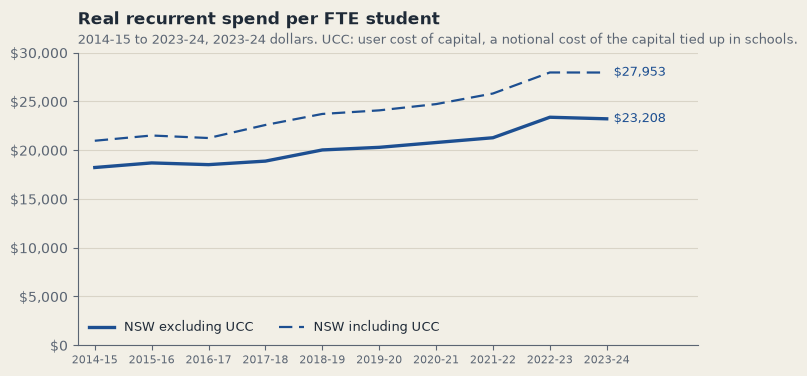

financial_year,2014-15,2015-16,2016-17,2017-18,2018-19,2019-20,2020-21,2021-22,2022-23,2023-24
component,,,,,,,,,,
excluding UCC,18215,18686,18509,18871,20016,20283,20777,21267,23369,23208
including UCC,20959,21497,21238,22577,23707,24074,24716,25803,27959,27953


In [5]:
plot_spend([S])
spend_series(S).round(0).T

### The spend split, 2023-24

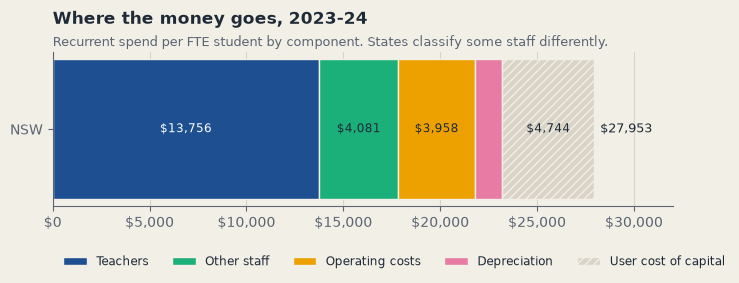

,Teachers,Other staff,Operating costs,Depreciation,User cost of capital
NSW,13756,4081,3958,1414,4744


In [6]:
plot_spend_split([S])
spend_split(S).to_frame(S).T

### School assets per student

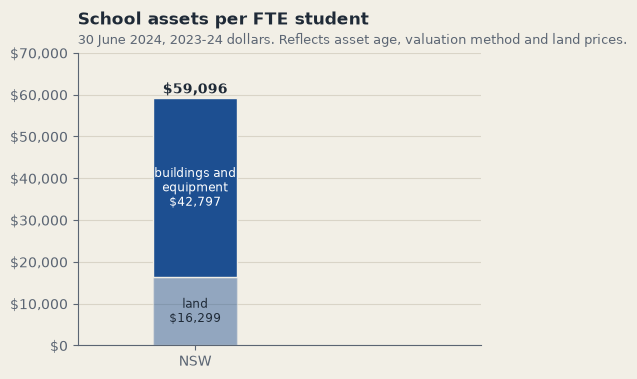

In [7]:
plot_assets([S])

### Students per teaching staff member

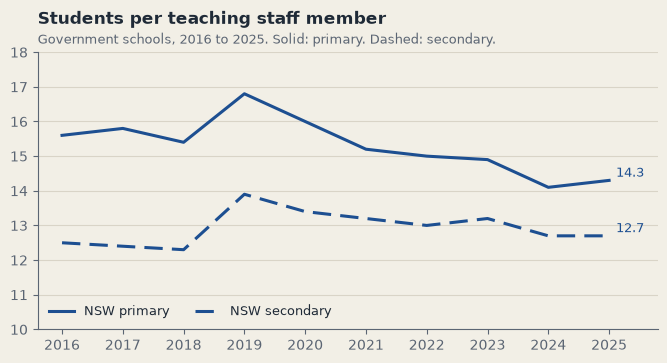

In [8]:
plot_ptr([S])

### Attendance: students at school on 90% or more of days

The y axis runs from 40% to 85%. There is no 2020 figure for either state, so the line breaks there. ROGS has no NSW
figure for 2016 or 2017.

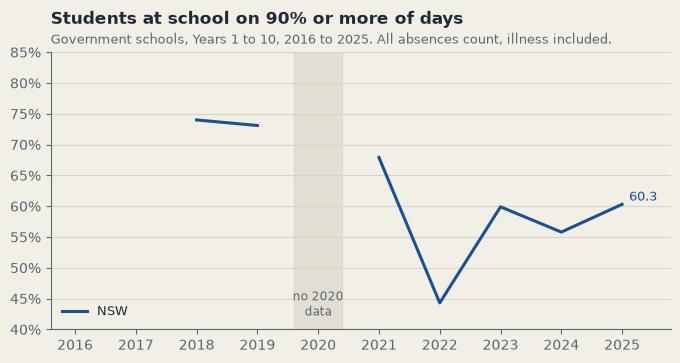

In [9]:
plot_attendance([S])

### Retention to Year 12

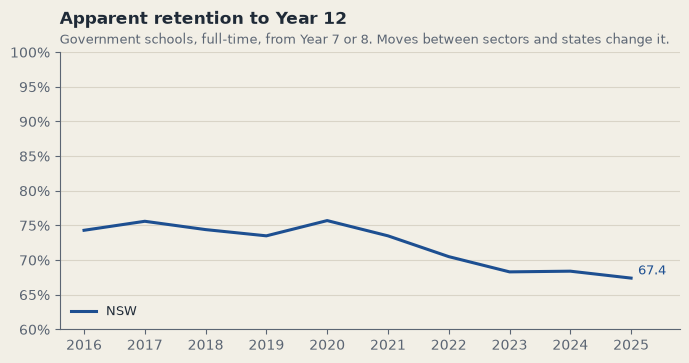

In [10]:
plot_retention([S])

### NAPLAN mean scores

The 2008 to 2022 scale and the 2023 scale are different scales, so the two panels are never joined. NAPLAN here covers
all school sectors. ACARA asks for 2026 Writing to be read with caution (a platform fault on 11 March 2026).

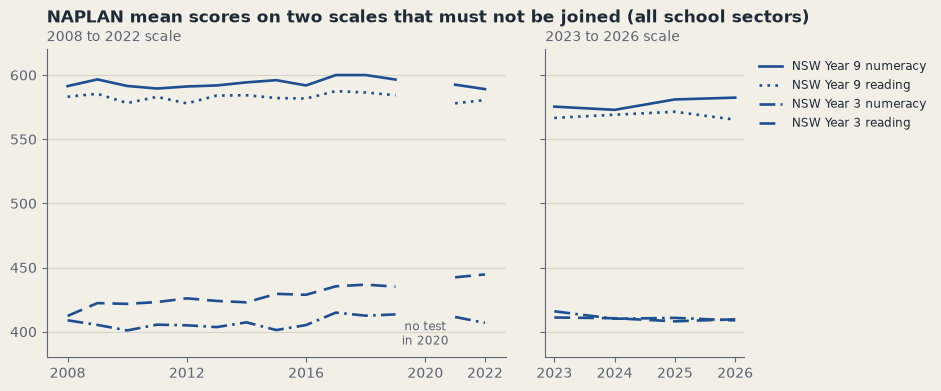

year_level,Year 3,Year 5,Year 7,Year 9
domain,,,,
Numeracy,408.8,501.2,558.2,582.4
Reading,409.7,492.1,542.1,565.2


In [11]:
plot_naplan([S])
old, new = naplan(S)
new[(new.year == 2026) & (new.domain != 'Writing')].pivot(index='domain', columns='year_level', values='mean')

### Inner-city grounds per student

Each outline in `data/nsw/sydney_outlines_joined.geojson` is measured here in GDA2020 Australian Albers (EPSG:9473), an equal-area grid, and divided by
the school's 2024 enrolment (headcount). Only schools marked `in_comparison` are compared:
mainstream schools whose outline passed the check. Grounds means land, buildings included, not floor space.

In [12]:
g = ground(S)
print(f'{len(g)} schools within 7 km, {int(g.in_comparison.sum())} compared; largest difference from the published area: {((g.area_albers_m2 - g.area_m2).abs() / g.area_m2).max():.3%}')
ground_medians(g)

86 schools within 7 km, 79 compared; largest difference from the published area: 0.003%


,schools,students_2024,median_m2_per_student,pooled_m2_per_student,schools_under_15_m2
Primary,62.0,23729.0,28.1,30.6,9.0
Secondary,16.0,13413.0,29.4,32.5,1.0


The map uses the same scale and the same bands in both cities.

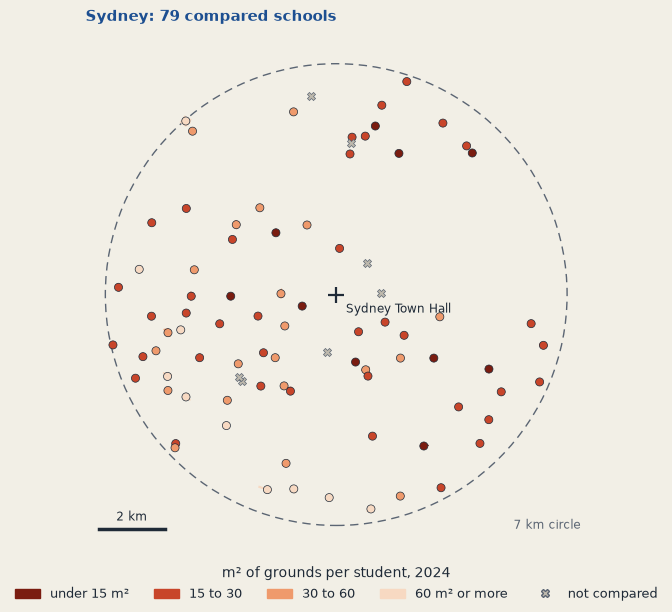

In [13]:
plot_ground_map([S])

In [14]:
g[g.in_comparison].nsmallest(5, 'm2_per_student')[['school_name', 'level', 'students_2024', 'area_albers_m2', 'm2_per_student']].round(1)

,school_name,level,students_2024,area_albers_m2,m2_per_student
13,Balmain Public School,Primary,335.0,3485.1,10.4
22,Woollahra Public School,Primary,701.0,7295.4,10.4
0,Ultimo Public School,Primary,478.0,5350.0,11.2
36,Neutral Bay Public School,Primary,690.0,8218.7,11.9
41,Bellevue Hill Public School,Primary,566.0,6988.5,12.3


### NSW only, no SA equivalent published

NSW publishes each school's ICSEA (Index of Community Socio-Educational Advantage, 1000 is the Australian average) and
its Resource Allocation Model (RAM) equity funding. SA does not publish a matching school-level table, so these have no
SA twin and do not appear in sections 2 or 3. They are shown next to grounds per student for the compared Sydney schools.
They do not show that one causes another.

79 compared schools; median ICSEA 1137; median RAM per student $784
Spearman rank correlations: ICSEA and grounds per student -0.36; ICSEA and RAM per student -0.64; RAM per student and grounds per student 0.32


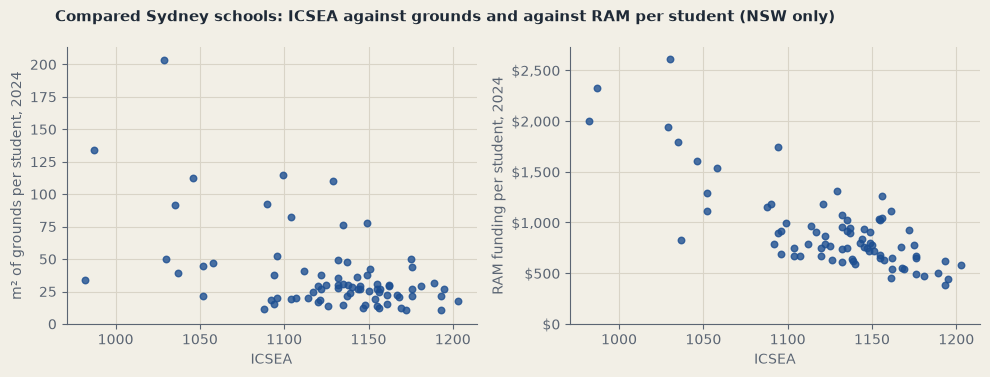

In [15]:
nsw = pd.read_csv(f'{DATA}/nsw/07_inner_city_schools.csv')
nsw = nsw[nsw.in_comparison].merge(ground('NSW')[['school_key', 'm2_per_student']].astype({'school_key': int}), on='school_key', validate='one_to_one')
rho_icsea = nsw[['nsw_only_icsea', 'm2_per_student']].corr('spearman').iloc[0, 1]
rho_ram = nsw[['nsw_only_icsea', 'nsw_only_ram_per_student_2024']].corr('spearman').iloc[0, 1]
rho_ram_ground = nsw[['nsw_only_ram_per_student_2024', 'm2_per_student']].corr('spearman').iloc[0, 1]
print(f'{len(nsw)} compared schools; median ICSEA {nsw.nsw_only_icsea.median():.0f}; median RAM per student ${nsw.nsw_only_ram_per_student_2024.median():,.0f}')
print(f'Spearman rank correlations: ICSEA and grounds per student {rho_icsea:.2f}; ICSEA and RAM per student {rho_ram:.2f}; RAM per student and grounds per student {rho_ram_ground:.2f}')
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].scatter(nsw.nsw_only_icsea, nsw.m2_per_student, s=22, color=COL['NSW'], alpha=0.8)
axes[0].set_xlabel('ICSEA'); axes[0].set_ylabel('m² of grounds per student, 2024'); axes[0].set_ylim(0, None); grid(axes[0], 'both')
axes[1].scatter(nsw.nsw_only_icsea, nsw.nsw_only_ram_per_student_2024, s=22, color=COL['NSW'], alpha=0.8)
axes[1].set_xlabel('ICSEA'); axes[1].set_ylabel('RAM funding per student, 2024'); axes[1].yaxis.set_major_formatter(money); axes[1].set_ylim(0, None); grid(axes[1], 'both')
fig.suptitle('Compared Sydney schools: ICSEA against grounds and against RAM per student (NSW only)', x=0.06, ha='left', fontsize=11, fontweight='bold')
plt.tight_layout(); plt.show()

## 2. SA view (the same code as the NSW view)

These are the cells of section 1 with `S = 'SA'`. Nothing else changes: the same functions, axes, bins and colours.

In [16]:
S = 'SA'

### Real spend per FTE student, 2014-15 to 2023-24

Recurrent spend per FTE government school student in 2023-24 dollars, including and excluding the user cost of
capital (UCC). The y axis runs from 0 to $30,000 in every view.

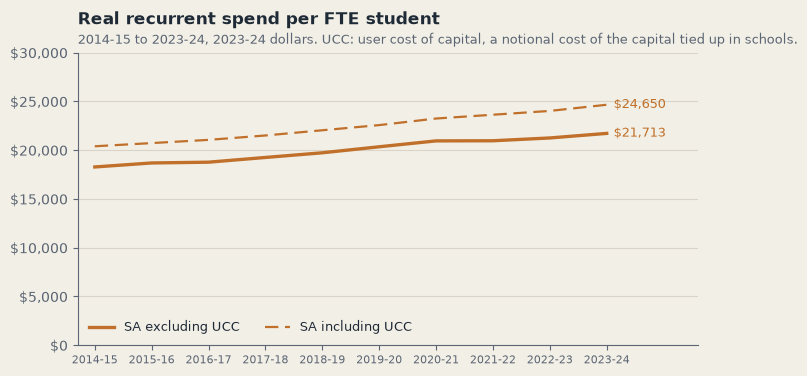

financial_year,2014-15,2015-16,2016-17,2017-18,2018-19,2019-20,2020-21,2021-22,2022-23,2023-24
component,,,,,,,,,,
excluding UCC,18271,18681,18761,19246,19724,20341,20945,20957,21245,21713
including UCC,20392,20719,21049,21499,22035,22563,23238,23627,24017,24650


In [17]:
plot_spend([S])
spend_series(S).round(0).T

### The spend split, 2023-24

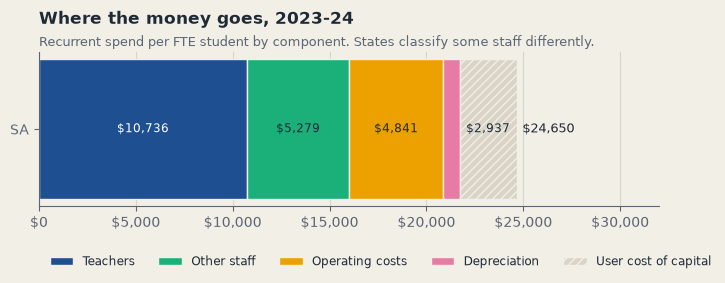

,Teachers,Other staff,Operating costs,Depreciation,User cost of capital
SA,10736,5279,4841,857,2937


In [18]:
plot_spend_split([S])
spend_split(S).to_frame(S).T

### School assets per student

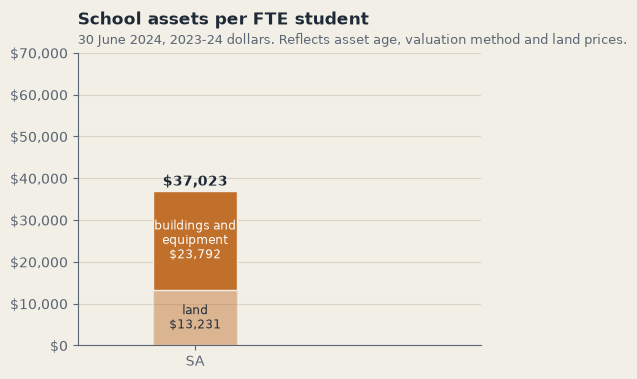

In [19]:
plot_assets([S])

### Students per teaching staff member

The 2022 step comes from Year 7 moving from primary to high school in SA.

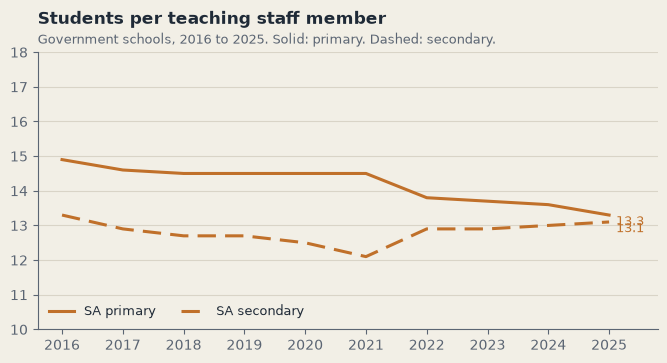

In [20]:
plot_ptr([S])

### Attendance: students at school on 90% or more of days

The y axis runs from 40% to 85%. There is no 2020 figure for either state, so the line breaks there. ROGS has no NSW
figure for 2016 or 2017.

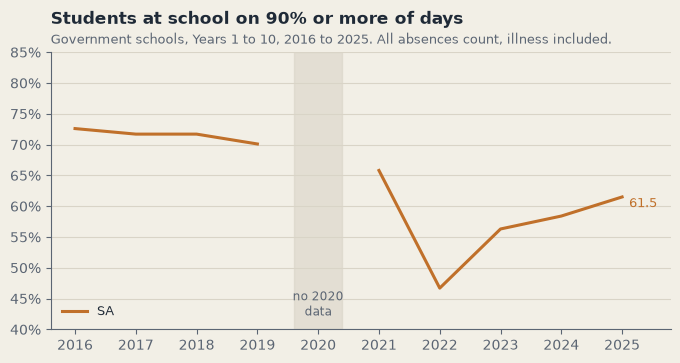

In [21]:
plot_attendance([S])

### Retention to Year 12

From 2022 the SA cohort starts at Year 7, which is now in high school.

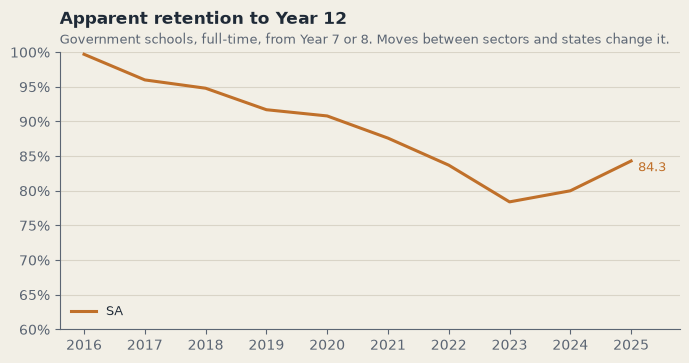

In [22]:
plot_retention([S])

### NAPLAN mean scores

The 2008 to 2022 scale and the 2023 scale are different scales, so the two panels are never joined. NAPLAN here covers
all school sectors. ACARA asks for 2026 Writing to be read with caution (a platform fault on 11 March 2026).

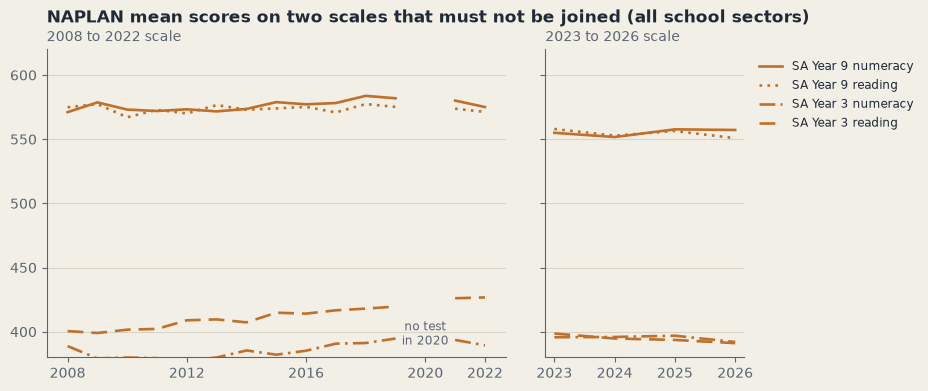

year_level,Year 3,Year 5,Year 7,Year 9
domain,,,,
Numeracy,392.0,482.4,533.3,557.2
Reading,391.1,479.4,524.8,550.8


In [23]:
plot_naplan([S])
old, new = naplan(S)
new[(new.year == 2026) & (new.domain != 'Writing')].pivot(index='domain', columns='year_level', values='mean')

### Inner-city grounds per student

Each outline in `data/sa/adelaide_outlines_joined.geojson` is measured here in GDA2020 Australian Albers (EPSG:9473), an equal-area grid, and divided by
the school's 2024 enrolment (FTE). Only schools marked `in_comparison` are compared:
mainstream schools whose outline passed the check. Grounds means land, buildings included, not floor space.

In Adelaide some schools use an oval next door. `median_with_adjoining_ovals` adds those ovals as an upper bound; the
main figure leaves them out, as in Sydney.

In [24]:
g = ground(S)
print(f'{len(g)} schools within 7 km, {int(g.in_comparison.sum())} compared; largest difference from the published area: {((g.area_albers_m2 - g.area_m2).abs() / g.area_m2).max():.3%}')
ground_medians(g)

54 schools within 7 km, 51 compared; largest difference from the published area: 0.001%


,schools,students_2024,median_m2_per_student,pooled_m2_per_student,schools_under_15_m2,median_with_adjoining_ovals
Primary,39.0,16452.1,42.4,50.9,0.0,46.1
Secondary,11.0,13285.5,34.4,34.2,3.0,44.0


The map uses the same scale and the same bands in both cities.

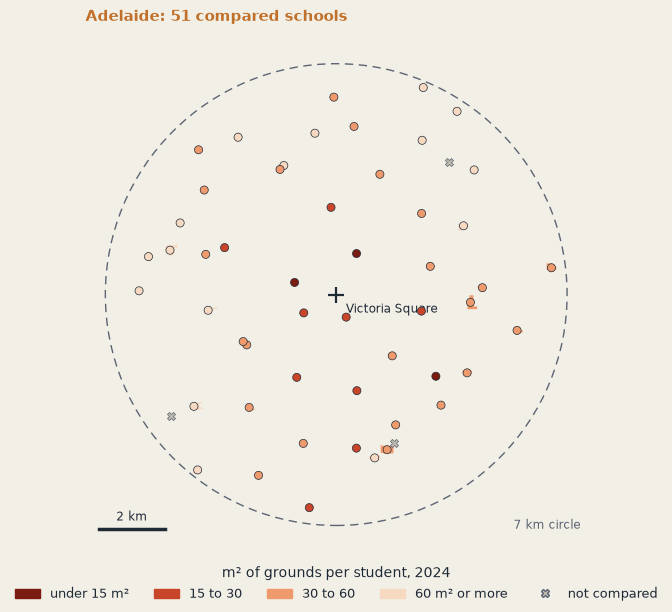

In [25]:
plot_ground_map([S])

In [26]:
g[g.in_comparison].nsmallest(5, 'm2_per_student')[['school_name', 'level', 'students_2024', 'area_albers_m2', 'm2_per_student']].round(1)

,school_name,level,students_2024,area_albers_m2,m2_per_student
2,Adelaide Botanic High School,Secondary,1197.0,7284.8,6.1
1,Adelaide High School,Secondary,1827.4,16220.4,8.9
15,Glenunga International High School,Secondary,2304.4,24964.0,10.8
46,Colonel Light Gardens Primary School,Primary,682.0,14409.8,21.1
7,Unley Primary School,Primary,461.0,10365.4,22.5


## 3. NSW and SA side by side

The same functions again, now called with both states. Every axis, band and colour is the one used above.

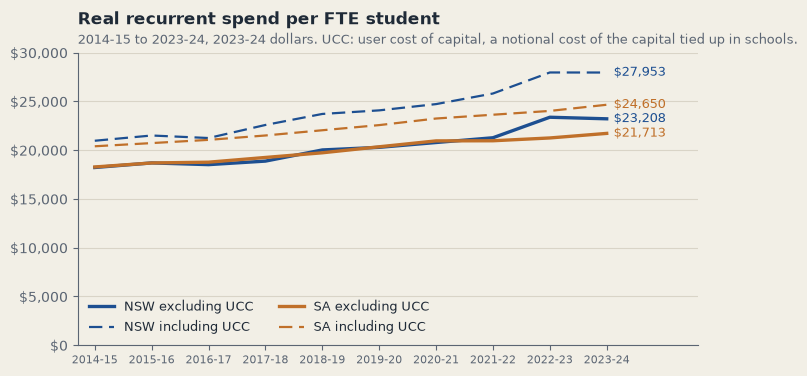

In [27]:
plot_spend(['NSW', 'SA'])

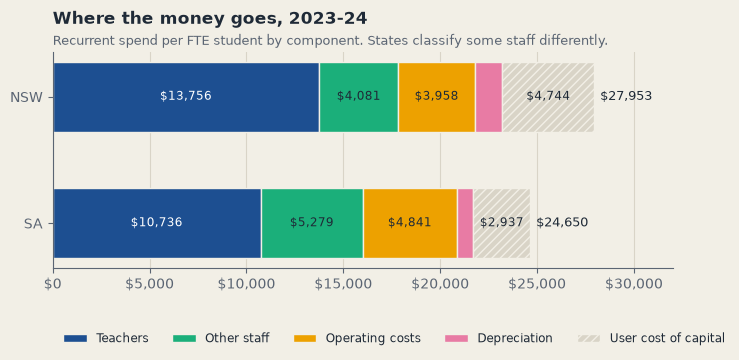

In [28]:
plot_spend_split(['NSW', 'SA'])

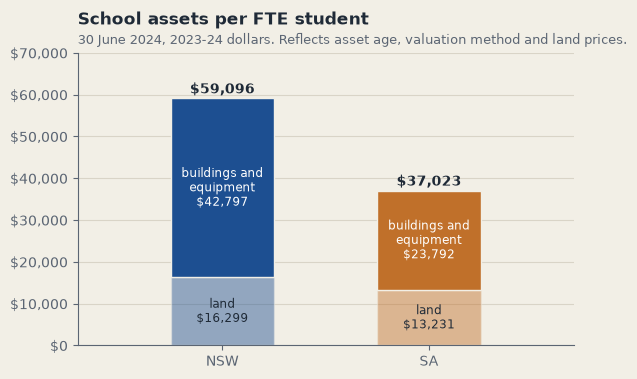

In [29]:
plot_assets(['NSW', 'SA'])

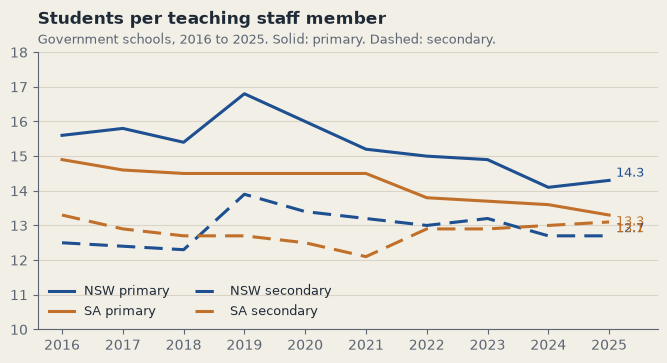

In [30]:
plot_ptr(['NSW', 'SA'])

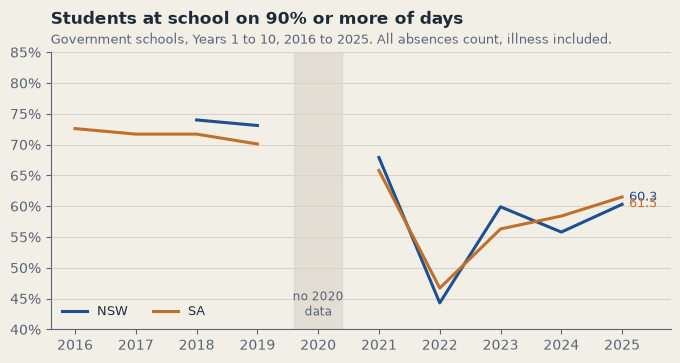

In [31]:
plot_attendance(['NSW', 'SA'])

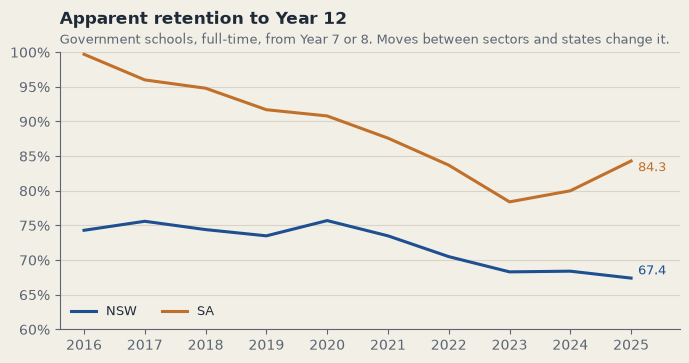

In [32]:
plot_retention(['NSW', 'SA'])

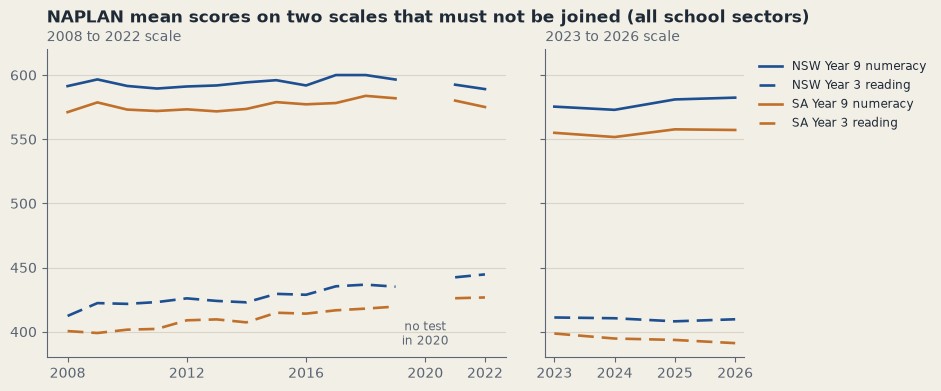

In [33]:
plot_naplan(['NSW', 'SA'])

### Grounds per student in the two inner cities

Sydney counts students by headcount, Adelaide by FTE. Both 2024 counts already have Year 7 in high school.

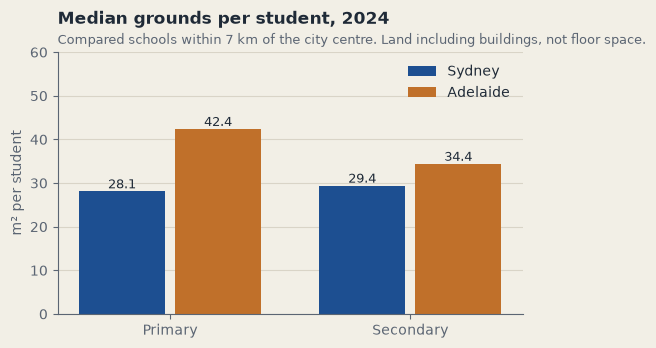

In [34]:
plot_ground_medians(['NSW', 'SA'])

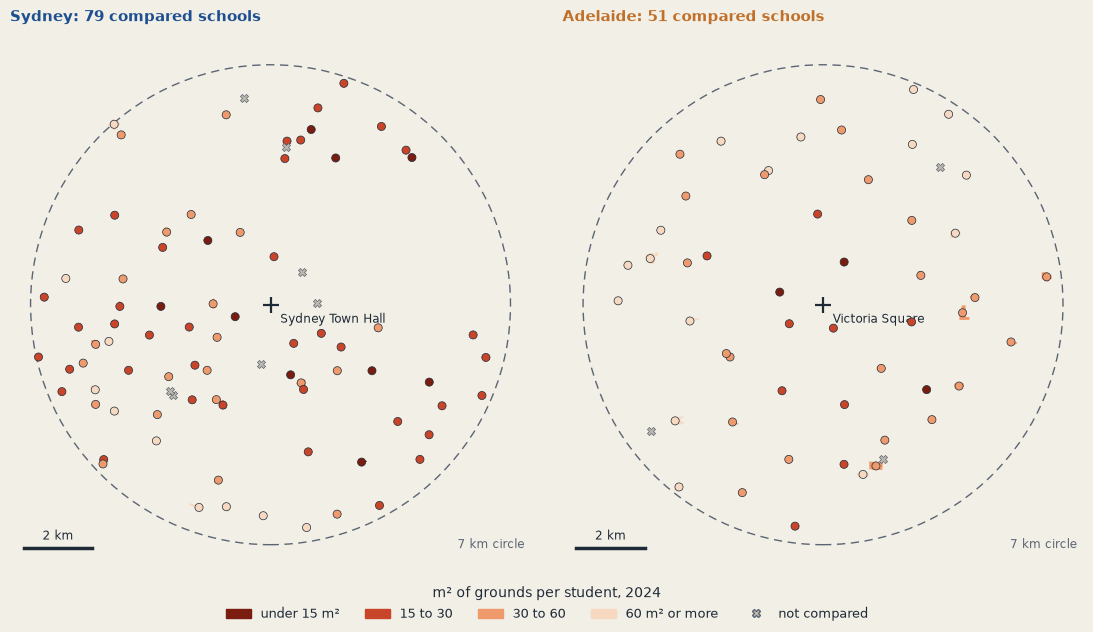

In [35]:
plot_ground_map(['NSW', 'SA'])

### The gaps: SA minus NSW

A positive gap means the SA figure is higher. The ROGS gaps are checked against the published comparison tables in
`data/comparison/`.

In [36]:
side = pd.concat([headline('NSW'), headline('SA')], axis=1)
side['SA minus NSW'] = side.SA - side.NSW
side['SA as % of NSW'] = 100 * side.SA / side.NSW
side.round(1)

,NSW,SA,SA minus NSW,SA as % of NSW
"spend per FTE student 2023-24, excluding UCC ($)",23208.0,21713.0,-1495.0,93.6
"spend per FTE student 2023-24, including UCC ($)",27953.0,24650.0,-3303.0,88.2
"school assets per FTE student, 30 June 2024 ($)",59096.0,37023.0,-22073.0,62.6
"students per teaching staff member, primary, 2025",14.3,13.3,-1.0,93.0
"students per teaching staff member, secondary, 2025",12.7,13.1,0.4,103.1
"students at school 90% or more of days, Years 1-10, 2025 (%)",60.3,61.5,1.2,102.0
"apparent retention Year 7/8 to 12, 2025 (%)",67.4,84.3,16.9,125.1
"NAPLAN Year 3 reading mean, 2026 (2023 scale)",409.7,391.1,-18.6,95.5
"NAPLAN Year 9 numeracy mean, 2026 (2023 scale)",582.4,557.2,-25.2,95.7
"inner-city grounds per student, primary median (m²)",28.1,42.4,14.3,150.9


In [37]:
comp = pd.read_csv(f'{DATA}/comparison/01_spend_per_student_components.csv')
comp = comp[(comp.financial_year == '2023-24') & (comp.school_level == 'All school levels')].set_index('component')
assert comp.loc[EXCL, 'SA_minus_NSW'] == side.loc['spend per FTE student 2023-24, excluding UCC ($)', 'SA minus NSW']
assert comp.loc[INCL, 'SA_minus_NSW'] == side.loc['spend per FTE student 2023-24, including UCC ($)', 'SA minus NSW']
c5 = pd.read_csv(f'{DATA}/comparison/05_attendance_retention_attainment.csv').set_index(['year', 'metric'])
for m, k in [(ATT90, 'students at school 90% or more of days, Years 1-10, 2025 (%)'), (RETENTION, 'apparent retention Year 7/8 to 12, 2025 (%)')]:
    assert abs(c5.loc[(2025, m), 'SA_minus_NSW'] - side.loc[k, 'SA minus NSW']) < 0.051, m
print('the gaps match data/comparison/')

the gaps match data/comparison/


## Checks

The headline numbers, recomputed from the GeoJSON and the ROGS tables, checked against the published values (within
0.1) and against `10_inner_city_summary.csv`. If an outline or a table changes, these catch it.

In [38]:
syd, adl = ground_medians(ground('NSW')), ground_medians(ground('SA'))
expected = {('NSW', 'Primary', 'median_m2_per_student'): 28.1, ('NSW', 'Secondary', 'median_m2_per_student'): 29.4,
            ('SA', 'Primary', 'median_m2_per_student'): 42.4, ('SA', 'Secondary', 'median_m2_per_student'): 34.4,
            ('SA', 'Primary', 'median_with_adjoining_ovals'): 46.1, ('SA', 'Secondary', 'median_with_adjoining_ovals'): 44.0}
for (s, lvl, col), want in expected.items():
    got = (syd if s == 'NSW' else adl).loc[lvl, col]
    assert abs(got - want) <= 0.1, (s, lvl, col, got, want)
# the SA upper bound from the published per-school column gives the same medians
up = ground('SA'); up = up[up.in_comparison].groupby('level').m2_per_student_2024_upper.median()
assert abs(up['Primary'] - 46.1) <= 0.1 and abs(up['Secondary'] - 44.0) <= 0.1, up
for s, m in [('NSW', syd), ('SA', adl)]:
    pub = rd(s, '10_inner_city_summary.csv').set_index('level')
    for lvl in ['Primary', 'Secondary']:
        assert abs(m.loc[lvl, 'median_m2_per_student'] - pub.loc[lvl, 'median_m2_per_student']) <= 0.1
        assert m.loc[lvl, 'schools'] == pub.loc[lvl, 'schools_compared']
for s, want in [('NSW', 23208), ('SA', 21713)]:
    got = spend_series(s).loc['2023-24', 'excluding UCC']
    assert abs(got - want) <= 0.1, (s, got)
print('all checks passed')
print(f"Sydney medians: primary {syd.loc['Primary', 'median_m2_per_student']}, secondary {syd.loc['Secondary', 'median_m2_per_student']} m² per student")
print(f"Adelaide medians: primary {adl.loc['Primary', 'median_m2_per_student']}, secondary {adl.loc['Secondary', 'median_m2_per_student']}; with adjoining ovals {adl.loc['Primary', 'median_with_adjoining_ovals']} and {adl.loc['Secondary', 'median_with_adjoining_ovals']}")
print(f"Spend per FTE student 2023-24 excluding UCC: NSW ${spend_series('NSW').loc['2023-24', 'excluding UCC']:,.0f}, SA ${spend_series('SA').loc['2023-24', 'excluding UCC']:,.0f}")

all checks passed
Sydney medians: primary 28.1, secondary 29.4 m² per student
Adelaide medians: primary 42.4, secondary 34.4; with adjoining ovals 46.1 and 44.0
Spend per FTE student 2023-24 excluding UCC: NSW $23,208, SA $21,713


## Caveats

- NSW enrolments are headcounts and SA enrolments are FTE; a part-time student counts as one in NSW and as a fraction
  in SA. The state ROGS figures are per FTE student in both.
- SA moved Year 7 from primary to high school in 2022, so SA primary and secondary series change base that year.
- Staged openings: a school without all its year groups in 2024 is left out of the medians in both cities. Inner Sydney
  High opened in 2020 with Year 7 and added a year group each year; 2025 is its first year with Years 7 to 12.
- NAPLAN was reset to a new scale in 2023 and moved to March; results from 2008 to 2022 cannot be compared with 2023
  on. NAPLAN figures here cover all school sectors.
- Grounds are land including buildings, not floor space or playground area. A vertical school can have far more floor
  space per student than grounds per student. Areas are approximate: accuracy depends on the cadastre, parcels and
  imagery the outlines came from.
- The measures sit side by side. Nothing here shows that spend, grounds, ICSEA or funding causes any result.